# Combinatorially Symmetric Cross-Validation

This native Julia companion preserves the original S&P 500 observations, thirty-two trial rules, symmetric partitions, population-standard-deviation scores and rank-logit decision. Saved public random innovations and moving-block bootstrap row positions reproduce the original seeded experiments; all simulated returns, scores, ranks and PBO estimates are calculated in Julia. Selected configuration indices are one-based except for the explicitly preserved zero-based preliminary example labels. Timing measurements describe this native execution. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

The starting point is a rectangular record of synchronized trial returns:

$$
M=(m_{t,n})\in\mathbb R^{T\times N}.
$$

Here, $M$ is the performance matrix, $m_{t,n}$ is the return of trial $n$ at observation $t$, $T$ is the common number of observations, and $N$ is the number of trials that were considered.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("19_backtest_overfitting");
using CSV, TOML, Printf, Combinatorics
using RiskLabAI.Backtest: probability_of_backtest_overfitting
using RiskLabAI.Validation: bagged_probability_of_backtest_overfitting,adaptive_probability_of_backtest_overfitting
prefix = "design"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter19-"*replace(name,"_"=>"-"))

function read_primitive(name)
    root = joinpath("..","data","chapter19_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".csv"]
    path = joinpath(root,name*".csv")
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values)==(metadata[],metadata["columns"])
    return values
end

function time_groups(count,partitions)
    base,remaining = divrem(count,partitions)
    boundaries = cumsum(vcat(0,[base+(index<=remaining) for index in 1:partitions]))
    return [collect(boundaries[index]+1:boundaries[index+1]) for index in 1:partitions]
end

function score_vector(values)
    deviations,means = vec(std(values;dims=1,corrected=false)),vec(mean(values;dims=1))
    return [deviation>0 ? average/deviation : 0. for (average,deviation) in zip(means,deviations)]
end

function cscv_records(values,partitions;names=["Trial "*string(index) for index in axes(values,2)],key=nothing)
    groups = time_groups(size(values,1),partitions)
    records = NamedTuple[]
    for (number,train_groups) in enumerate(combinations(1:partitions,partitions÷2))
        test_groups = setdiff(1:partitions,train_groups)
        train,test = reduce(vcat,groups[train_groups]),reduce(vcat,groups[test_groups])
        training_scores,testing_scores = score_vector(values[train,:]),score_vector(values[test,:])
        selected = argmax(training_scores)
        ranks = invperm(sortperm(testing_scores))
        rank = ranks[selected]
        relative = rank/(size(values,2)+1)
        logit = log(relative/(1-relative))
        push!(records,(combination=number,train=join(train_groups,", "),test=join(test_groups,", "),n_train=length(train),n_test=length(test),selected=selected,name=names[selected],in_sample=training_scores[selected],out_sample=testing_scores[selected],rank=rank,relative=relative,logit=logit,overfit=Int(logit<=0)))
    end
    result = DataFrame(records)
    rename!(result,["Combination","Training groups","Testing groups","Training observations","Testing observations","Selected trial","Selected name","In-sample score","Out-of-sample score","Out-of-sample rank","Relative rank","Logit","Overfit"])
    key===nothing || save_data(result,paths,key*"_records")
    return result
end

function manual_pbo(values,partitions)
    records = cscv_records(values,partitions)
    return mean(records.Overfit),records.Logit
end

function histogram_panel(values,bins,color,key;density=false,title_text="")
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = zeros(Int,bins)
    for value in values
        counts[searchsortedlast(edges,value)] += 1
    end
    widths = diff(edges)
    heights = density ? counts./sum(counts)./widths : Float64.(counts)
    @assert sum(counts)==length(values)
    save_data(DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts,height=heights),paths,key*"_histogram")
    panel = bar((edges[1:end-1].+edges[2:end])./2,heights;bar_width=widths,color,fillalpha=.9,linecolor=palette.background,label="",xlabel="Logit",ylabel=density ? "Density" : "Combinations",title=title_text)
    vline!(panel,[0.];color=palette.rose,label="",linewidth=1.5)
    return panel
end

function average_ranks(values)
    order = sortperm(values)
    ranks = zeros(length(values))
    first_position = 1
    while first_position<=length(values)
        last_position = first_position
        while last_position<length(values) && values[order[last_position+1]]==values[order[first_position]]
            last_position += 1
        end
        ranks[order[first_position:last_position]] .= (first_position+last_position)/2
        first_position = last_position+1
    end
    return ranks
end


average_ranks (generic function with 1 method)

## Defining the public trial family

10×2 DataFrame
 Row │ Field               Value
     │ String              String
─────┼───────────────────────────────────────────────────────
   1 │ Series              S&P 500
   2 │ Provider            Federal Reserve Bank of St. Louis
   3 │ Source              https://fred.stlouisfed.org/grap…
   4 │ Retrieved           2026-09-28
   5 │ First price         2016-09-26
   6 │ Last price          2025-12-31
   7 │ Price observations  2,330
   8 │ Trial observations  2,090
   9 │ Trials              32

Row,Trial,Rule,Fast span,Slow span,Name
,Int64,String,Int64,Int64,String
1,1,Trend,3,30,Trend 3/30
2,2,Reversal,3,30,Reversal 3/30
3,3,Trend,3,60,Trend 3/60
4,4,Reversal,3,60,Reversal 3/60
5,5,Trend,3,120,Trend 3/120
6,6,Reversal,3,120,Reversal 3/120
7,7,Trend,3,240,Trend 3/240
8,8,Reversal,3,240,Reversal 3/240
9,9,Trend,5,30,Trend 5/30


Row,Trial,Name,Annual return,Annual volatility,Sharpe ratio,Cumulative return
,Int64,String,Float64,Float64,Float64,Float64
1,1,Trend 3/30,0.0711689,0.19312,0.368521,0.804439
2,2,Reversal 3/30,-0.0711689,0.19312,-0.368521,-0.445811
3,3,Trend 3/60,0.0487906,0.193148,0.252607,0.498781
4,4,Reversal 3/60,-0.0487906,0.193148,-0.252607,-0.332791
5,5,Trend 3/120,0.0560282,0.19314,0.290091,0.591502
6,6,Reversal 3/120,-0.0560282,0.19314,-0.290091,-0.371663
7,7,Trend 3/240,0.03849,0.193157,0.199268,0.376058
8,8,Reversal 3/240,-0.03849,0.193157,-0.199268,-0.273286
9,9,Trend 5/30,0.0866475,0.193095,0.448729,1.05161


Row,Rule,Fast span,Trials,Smallest slow span,Largest slow span
,String,Int64,Int64,Int64,Int64
1,Reversal,3,4,30,240
2,Reversal,5,4,30,240
3,Reversal,10,4,30,240
4,Reversal,20,4,30,240
5,Trend,3,4,30,240
6,Trend,5,4,30,240
7,Trend,10,4,30,240
8,Trend,20,4,30,240


Row,Trial,Name,Annual return,Annual volatility,Sharpe ratio,Cumulative return
,Int64,String,Float64,Float64,Float64,Float64
1,9,Trend 5/30,0.0866475,0.193095,0.448729,1.05161
2,27,Trend 20/60,0.0798448,0.193107,0.413474,0.939063
3,13,Trend 5/120,0.0716248,0.19312,0.370883,0.811275
4,1,Trend 3/30,0.0711689,0.19312,0.368521,0.804439
5,21,Trend 10/120,0.068841,0.193124,0.35646,0.769935
6,17,Trend 10/30,0.0661505,0.193128,0.342523,0.730879
7,5,Trend 3/120,0.0560282,0.19314,0.290091,0.591502
8,3,Trend 3/60,0.0487906,0.193148,0.252607,0.498781


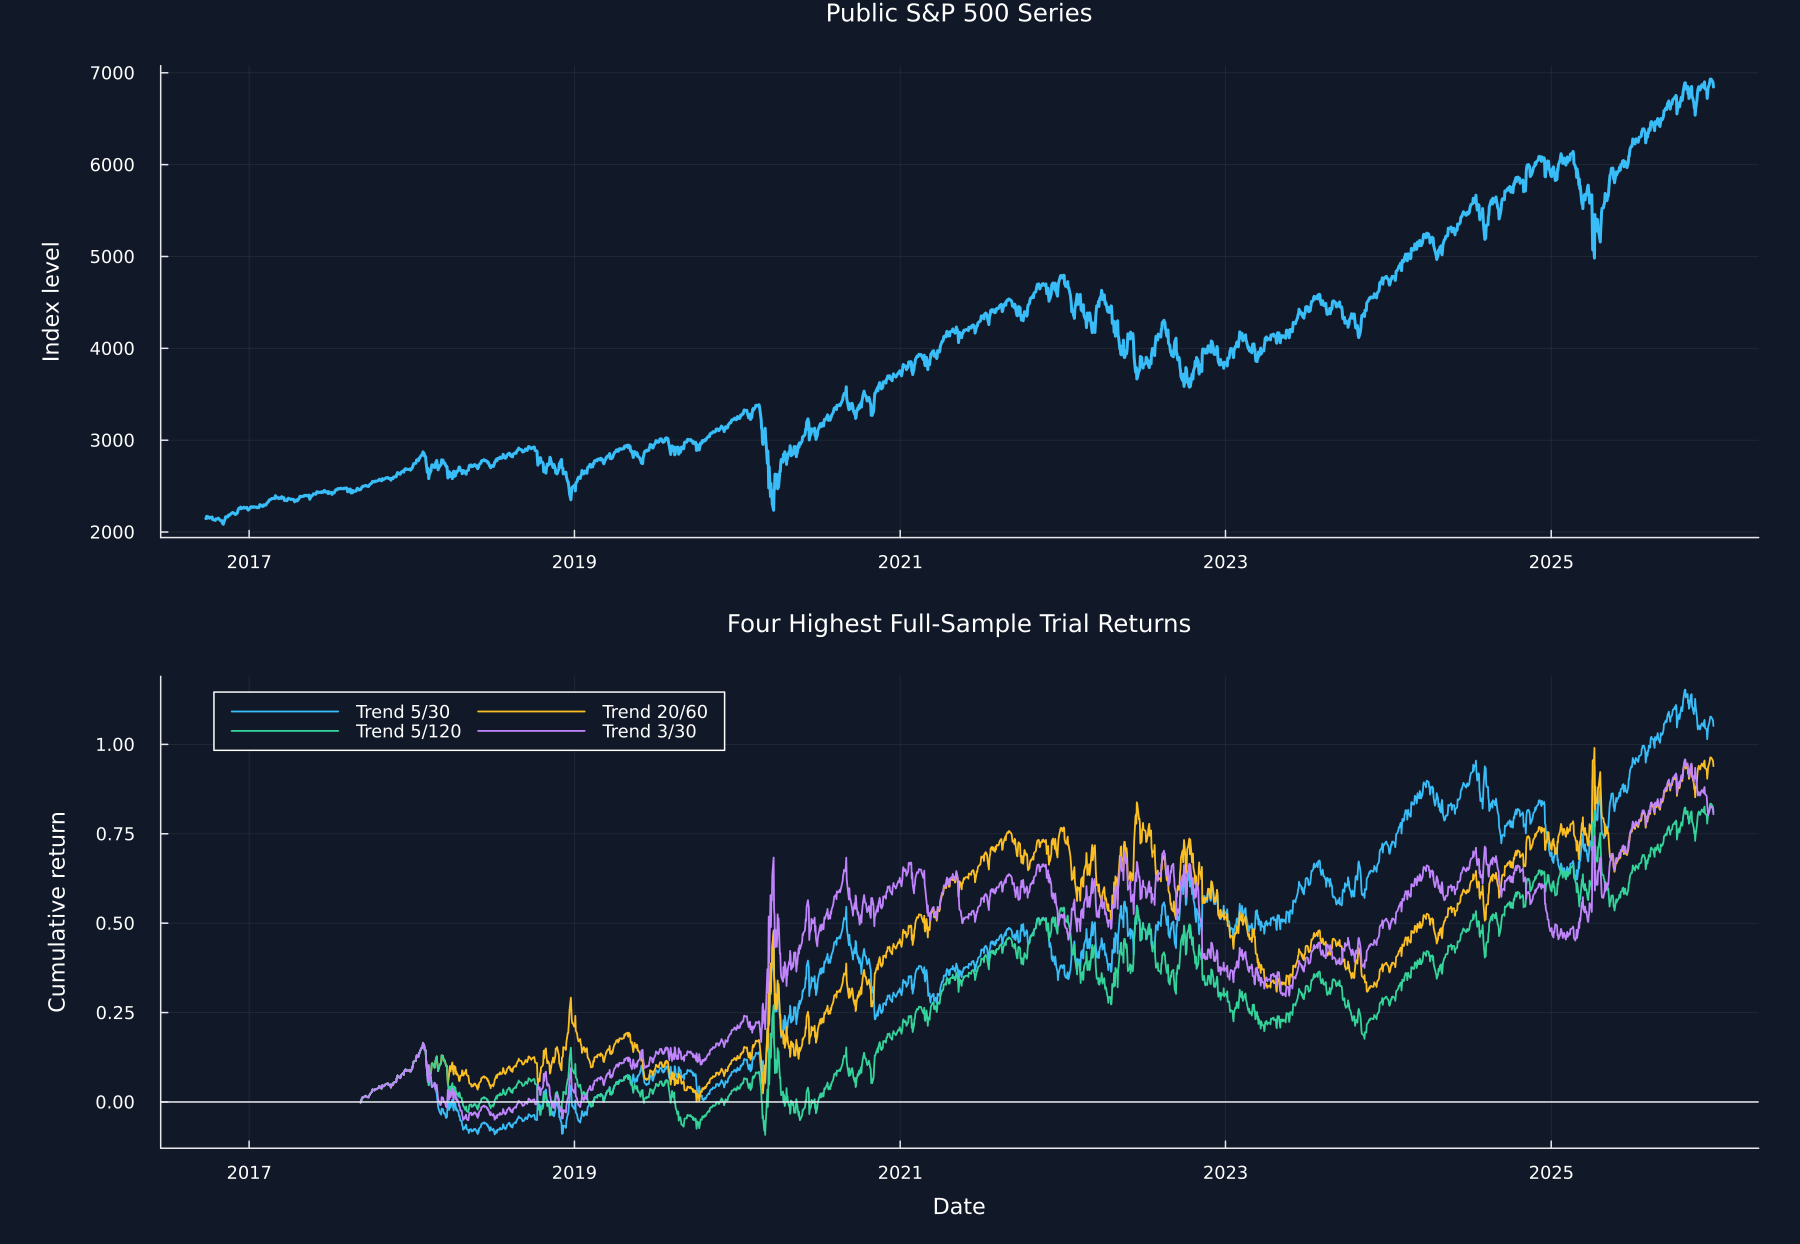

In [2]:
source_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
data_provenance = DataFrame("Field"=>["Series","Provider","Source","Retrieved","First price","Last price","Price observations","Trial observations","Trials"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis",source_url,"2026-09-28",string(first(price_dates)),string(last(price_dates)),"2,330","2,090","32"])
full_performance = DataFrame("Trial"=>collect(1:32),"Name"=>names_trials,"Annual return"=>vec(mean(performances;dims=1)).*252,"Annual volatility"=>vec(std(performances;dims=1,corrected=false)).*sqrt(252),"Sharpe ratio"=>score_vector(performances).*sqrt(252),"Cumulative return"=>exp.(vec(sum(performances;dims=1))).-1)
trial_family_summary = combine(groupby(strategy_catalog,["Rule","Fast span"];sort=true),nrow=>"Trials","Slow span"=>minimum=>"Smallest slow span","Slow span"=>maximum=>"Largest slow span")
leading_trials = first(sort(full_performance,["Sharpe ratio","Trial"];rev=[true,false]),8)
table(data_provenance,"data_provenance","Public observations used for the symmetric cross-validation experiment.")
table(strategy_catalog,"strategy_catalog","The thirty-two synchronized strategy trials.")
table(full_performance,"full_sample_performance","Full-sample descriptions of the strategy trials.")
table(trial_family_summary,"trial_family_summary","Counts and slow-span ranges in the public trial family.")
table(leading_trials,"leading_full_sample_trials","The eight highest full-sample Sharpe ratios in the public trial family.")
ticks = Date.(2017:2:2025,1,1)
tick_spec = (Dates.value.(ticks),string.(year.(ticks)))
p1 = plot(Dates.value.(price_dates),prices;color=palette.cyan,label="",ylabel="Index level",title="Public S&P 500 Series",xticks=tick_spec)
p2 = plot(;xlabel="Date",ylabel="Cumulative return",title="Four Highest Full-Sample Trial Returns",xticks=tick_spec,legend=:topleft,legendcolumns=2)
for (trial,color) in zip(leading_trials.Trial[1:4],[palette.cyan,palette.amber,palette.green,violet])
    plot!(p2,Dates.value.(dates),exp.(cumsum(performances[:,trial])).-1;color,label=names_trials[trial],linewidth=1.2)
end
hline!(p2,[0.];color=palette.text,label="",linewidth=1)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1200,830),left_margin=10Plots.mm),paths,"public_sp500_trials")


An even number of consecutive groups divides the rows without changing their order:

$$
M=\begin{bmatrix}M_1^{\mathsf T}&\cdots&M_S^{\mathsf T}\end{bmatrix}^{\mathsf T},
\qquad M_s\in\mathbb R^{T_s\times N},
\qquad \sum_{s=1}^{S}T_s=T.
$$

Here, $S$ is an even number of time groups, $M_s$ is group $s$, $T_s$ is its number of observations, $N$ is the number of trials, and the transpose marks show that the groups are joined down the rows in their original time order.

## Symmetric Combinations

Choosing half of the groups for training produces this many ordered training and testing assignments:

$$
C_S=\binom{S}{S/2}=\frac{S!}{(S/2)!(S/2)!}.
$$

Here, $C_S$ is the number of symmetric combinations, $S$ is the even number of groups, $S/2$ is the number assigned to each side, and the factorial formula counts every distinct choice of training groups whose complement becomes the testing set.

Row,Group,First date,Last date,Observations
,Int64,String,String,Int64
1,1,2017-09-08,2018-09-21,262
2,2,2018-09-24,2019-10-08,262
3,3,2019-10-09,2020-10-20,261
4,4,2020-10-21,2021-11-02,261
5,5,2021-11-03,2022-11-15,261
6,6,2022-11-16,2023-11-30,261
7,7,2023-12-01,2024-12-13,261
8,8,2024-12-16,2025-12-31,261


Row,Quantity,Value
,String,Int64
1,Time groups,8
2,Groups on each side,4
3,Symmetric combinations,70
4,Complement pairs,35
5,Smallest training set,1044
6,Largest training set,1046
7,Smallest testing set,1044
8,Largest testing set,1046


Row,Combination,Training groups,Testing groups,Training observations,Testing observations
,Int64,String,String,Int64,Int64
1,1,"1, 2, 3, 4","5, 6, 7, 8",1046,1044
2,2,"1, 2, 3, 5","4, 6, 7, 8",1046,1044
3,3,"1, 2, 3, 6","4, 5, 7, 8",1046,1044
4,4,"1, 2, 3, 7","4, 5, 6, 8",1046,1044
5,5,"1, 2, 3, 8","4, 5, 6, 7",1046,1044
6,6,"1, 2, 4, 5","3, 6, 7, 8",1046,1044
7,7,"1, 2, 4, 6","3, 5, 7, 8",1046,1044
8,8,"1, 2, 4, 7","3, 5, 6, 8",1046,1044
9,9,"1, 2, 4, 8","3, 5, 6, 7",1046,1044


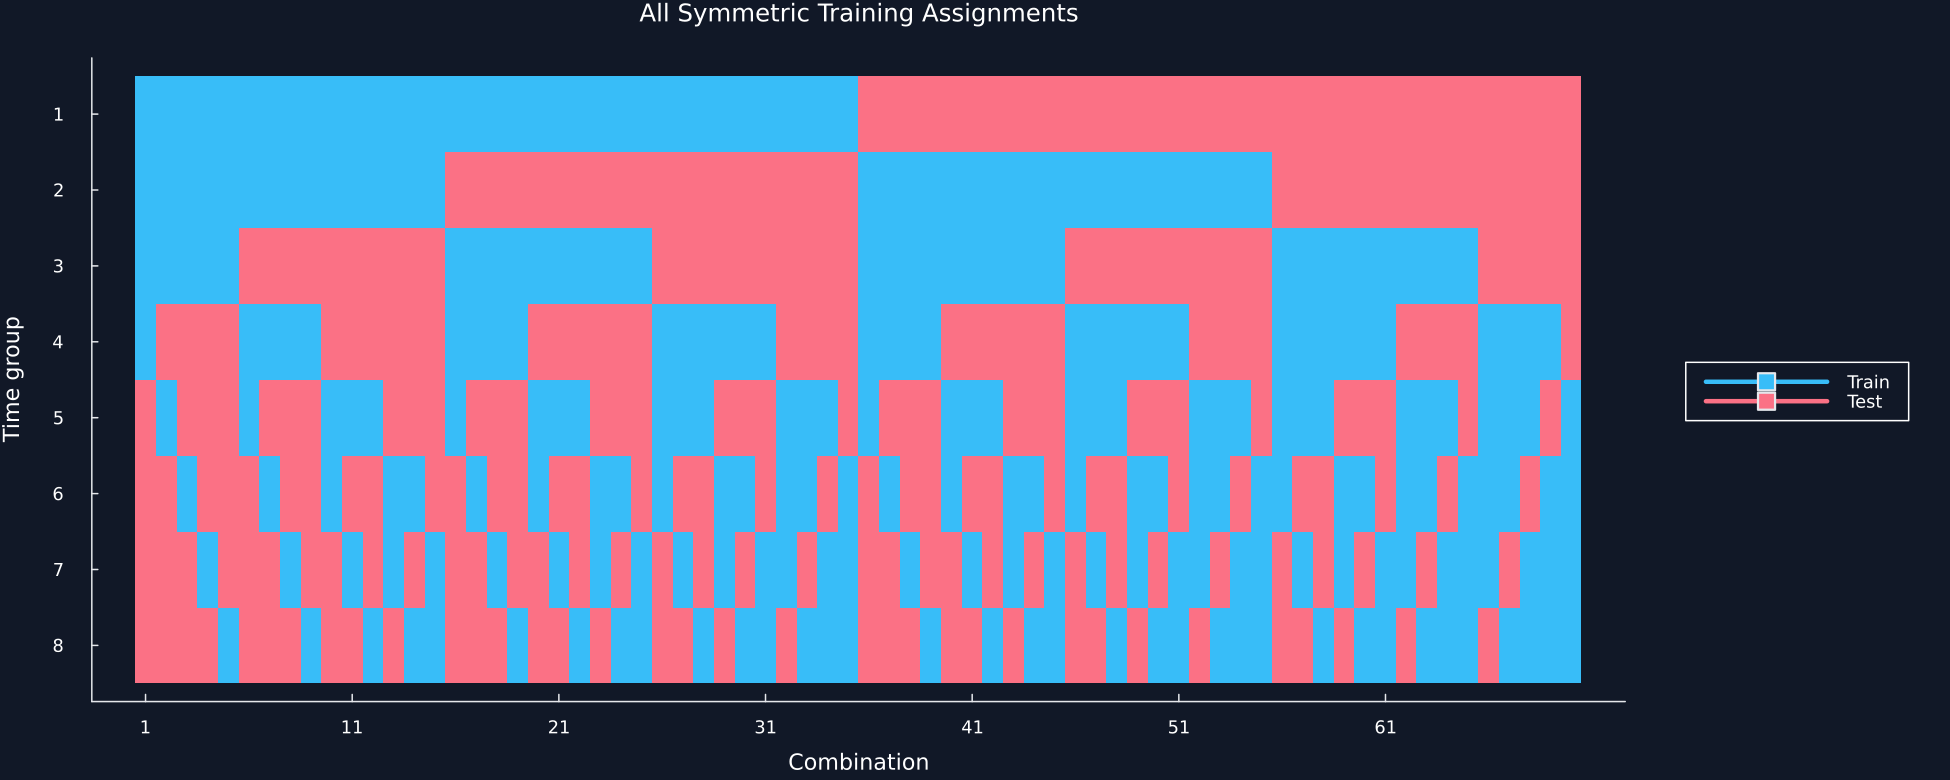

In [3]:
n_partitions = 8
groups = time_groups(size(performances,1),n_partitions)
group_summary = DataFrame("Group"=>collect(1:8),"First date"=>[string(dates[first(indices)]) for indices in groups],"Last date"=>[string(dates[last(indices)]) for indices in groups],"Observations"=>length.(groups))
records = cscv_records(performances,8;names=names_trials,key="design")
combinations_list = collect(combinations(1:8,4))
complement_pairs = Set(Tuple(sort([Tuple(train),Tuple(setdiff(1:8,train))])) for train in combinations_list)
combination_summary = DataFrame("Quantity"=>["Time groups","Groups on each side","Symmetric combinations","Complement pairs","Smallest training set","Largest training set","Smallest testing set","Largest testing set"],"Value"=>[8,4,nrow(records),length(complement_pairs),minimum(records[!,"Training observations"]),maximum(records[!,"Training observations"]),minimum(records[!,"Testing observations"]),maximum(records[!,"Testing observations"])])
split_audit = select(first(records,14),1:5)
table(group_summary,"time_group_summary","Consecutive groups in the public symmetric split.")
table(combination_summary,"combination_summary","Counts for the public symmetric split.")
table(split_audit,"split_audit","The first fourteen symmetric training and testing assignments.")
occupancy = zeros(Int,8,70)
for (column,train) in enumerate(combinations_list)
    occupancy[train,column] .= 1
end
save_data(DataFrame(occupancy,:auto),paths,"symmetric_split_map")
figure = heatmap(1:70,1:8,occupancy;color=cgrad([palette.rose,palette.cyan],categorical=true),clims=(-.5,1.5),colorbar=false,yflip=true,xticks=1:10:70,yticks=1:8,title="All Symmetric Training Assignments",xlabel="Combination",ylabel="Time group",size=(1300,520),grid=false,legend=:outerright)
for (color,label) in [(palette.cyan,"Train"),(palette.rose,"Test")]
    plot!(figure,[NaN],[NaN];marker=:rect,color,label,linewidth=3)
end
save_figure(figure,paths,"symmetric_split_map")


Every assignment has a complementary assignment with the two sides exchanged:

$$
A\subset\{1,\ldots,S\},\ |A|=S/2
\quad\Longrightarrow\quad
A^{\mathsf c}\subset\{1,\ldots,S\},\ |A^{\mathsf c}|=S/2.
$$

Here, $A$ is one set of training groups, $A^{\mathsf c}$ is its complement, $|A|$ denotes the number of groups in $A$, and the equality of the two sizes makes it possible to reuse each training half as a testing half.

## Preliminary Ranking Example

A simple rank summary averages a trial's rank across repeated splits:

$$
\overline q_n=\frac{1}{K}\sum_{k=1}^{K}q_{n,k}.
$$

Here, $q_{n,k}$ is the descending performance rank of trial $n$ in split $k$, $K$ is the number of splits, and $\overline q_n$ is the mean rank, so a smaller value indicates more consistently high performance.

Row,Trial,Split 1,Split 2,Split 3,Split 4
,Int64,Float64,Float64,Float64,Float64
1,0,0.37454,0.950714,0.731994,0.598658
2,1,0.9,0.2,0.1,0.3
3,2,0.601115,0.708073,0.0205845,0.96991
4,3,0.8,0.75,0.85,0.7
5,4,0.304242,0.524756,0.431945,0.291229
6,5,0.611853,0.139494,0.292145,0.366362


Row,Trial,Mean rank,Rank spread
,Int64,Float64,Float64
1,3,1.75,0.5
2,0,2.75,1.70783
3,2,3.5,2.08167
4,1,4.0,2.0
5,5,4.25,1.25831
6,4,4.75,1.5


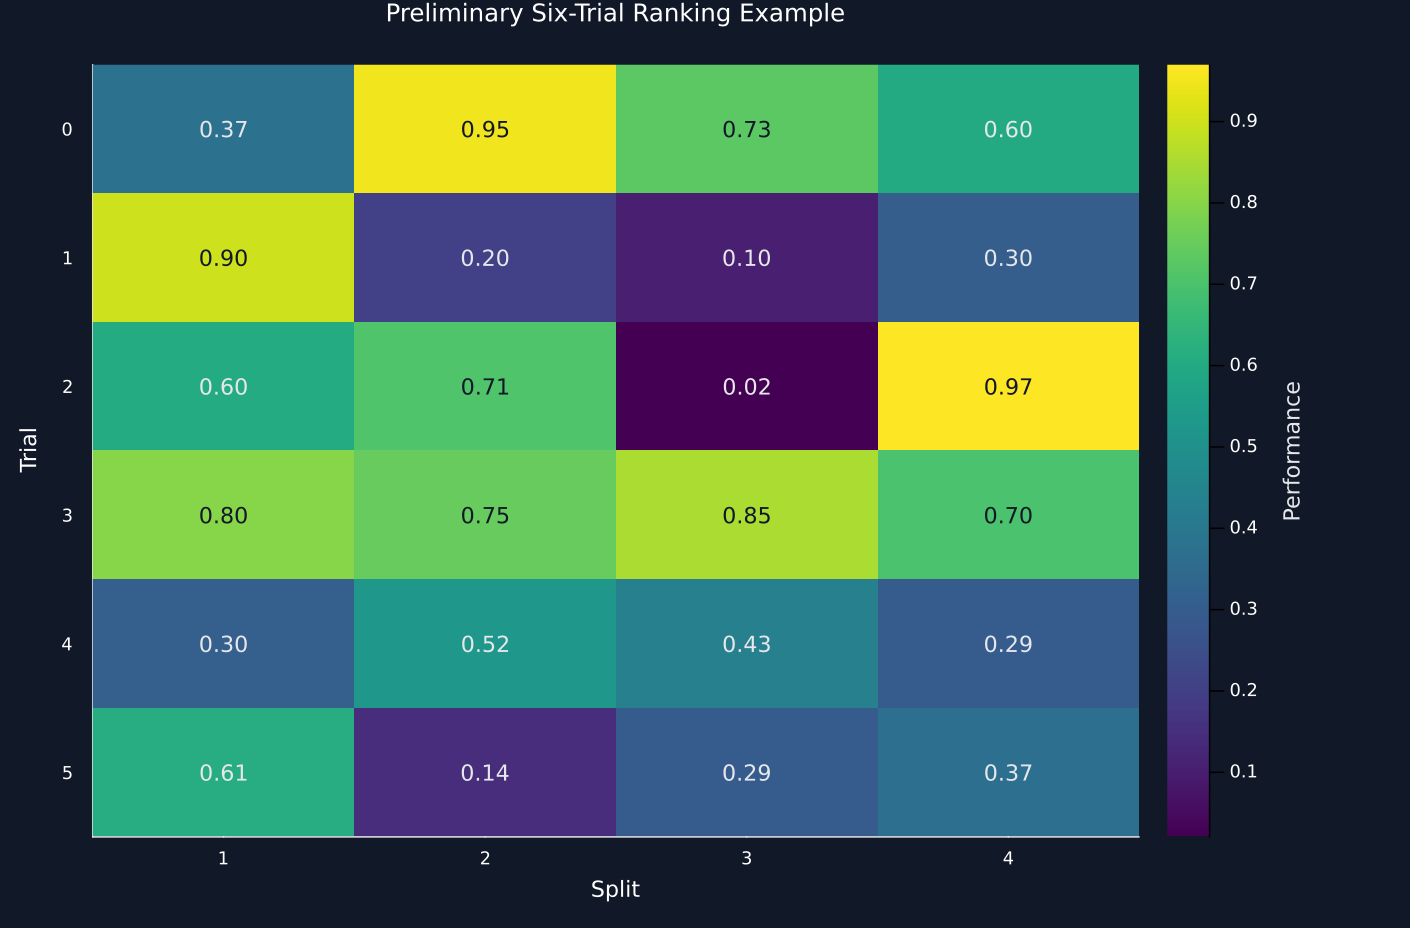

In [4]:
preliminary_matrix = read_primitive("preliminary_uniform")
preliminary_matrix[4,:] = [.8,.75,.85,.7]
preliminary_matrix[2,:] = [.9,.2,.1,.3]
preliminary_ranks = reduce(hcat,[average_ranks(-preliminary_matrix[:,column]) for column in 1:4])
preliminary_summary = DataFrame("Trial"=>collect(0:5),"Mean rank"=>vec(mean(preliminary_ranks;dims=2)),"Rank spread"=>vec(std(preliminary_ranks;dims=2)))
sort!(preliminary_summary,["Mean rank","Trial"])
preliminary_table = DataFrame(preliminary_matrix,["Split "*string(index) for index in 1:4])
insertcols!(preliminary_table,1,"Trial"=>collect(0:5))
table(preliminary_table,"preliminary_performance_matrix","The preliminary six-trial ranking example.")
table(preliminary_summary,"preliminary_rank_summary","Mean ranks in the preliminary ranking example.")
save_data(DataFrame(preliminary_ranks,:auto),paths,"preliminary_ranks")
figure = heatmap(1:4,0:5,preliminary_matrix;color=:viridis,colorbar_title="Performance",yflip=true,xticks=1:4,yticks=0:5,title="Preliminary Six-Trial Ranking Example",xlabel="Split",ylabel="Trial",size=(940,620),right_margin=16Plots.mm,grid=false)
for row in 1:6, column in 1:4
    color = preliminary_matrix[row,column]>.62 ? palette.background : palette.text
    annotate!(figure,column,row-1,text(@sprintf("%.2f",preliminary_matrix[row,column]),10,color,:center))
end
save_figure(figure,paths,"preliminary_ranking_example")


## Tests

In [5]:
@assert issorted(price_dates)
@assert allunique(price_dates)
@assert size(performances,2)==32
@assert size(strategy_catalog)==(32,5)
@assert size(trial_family_summary)==(8,5)
@assert size(leading_trials)==(8,6)
@assert all(isfinite,performances)
@assert nrow(records)==binomial(8,4)==70
@assert length(complement_pairs)==35
@assert all(==(4),sum(occupancy;dims=1))
@assert all(==(35),sum(occupancy;dims=2))
@assert maximum(group_summary.Observations)-minimum(group_summary.Observations)<=1
@assert first(preliminary_summary.Trial)==3
@assert last(preliminary_summary.Trial)==4
@assert isfile(joinpath(paths.figures,"public_sp500_trials.pdf"))
@assert isfile(joinpath(paths.figures,"symmetric_split_map.pdf"))
@assert isfile(joinpath(paths.figures,"preliminary_ranking_example.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"strategy_catalog.tex"))
@assert isfile(joinpath(paths.tables,"full_sample_performance.tex"))
@assert isfile(joinpath(paths.tables,"trial_family_summary.tex"))
@assert isfile(joinpath(paths.tables,"leading_full_sample_trials.tex"))
@assert isfile(joinpath(paths.tables,"time_group_summary.tex"))
@assert isfile(joinpath(paths.tables,"combination_summary.tex"))
@assert isfile(joinpath(paths.tables,"split_audit.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_performance_matrix.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_rank_summary.tex"))
